# Muestras que comparten ruido: covarianza, promedio y filtrado

**Tema 4 · Apartados 4.4–4.5 · Demostración orientativa: 10–20 minutos.**

Ver por qué promediar muestras correladas puede ayudar poco y cómo un filtro crea memoria y cambia el espectro.

## Cómo experimentar
Ejecuta todo de arriba abajo. Cambia un parámetro, predice qué ocurrirá y vuelve a ejecutar todas las celdas.
En Colab: *Entorno de ejecución → Ejecutar todas*. En Jupyter: *Kernel → Restart Kernel and Run All Cells*.
Los comentarios `#@param` permiten formularios en Colab; en Jupyter puedes editar los valores.

En la web, «Abrir en Colab» abre este cuaderno en el navegador.
La descarga .ipynb permite abrirlo en Jupyter o importarlo en Colab.
La vista HTML muestra resultados guardados; no recalcula las gráficas. Los cambios en Colab no modifican el original.
Los datos se generan en el propio cuaderno. La semilla reproduce una realización, no elimina la variabilidad estadística.
No se instalan paquetes ni se descargan datos. Solo se necesitan NumPy y Matplotlib.

## Modelo y pregunta

**Primera parte:** repetimos una observación constante h: y1=h+w1, y2=h+w2.
Los ruidos tienen media cero, varianza sigma² y covarianza rho sigma². Cada pareja es independiente de las otras.
Los generamos a partir de gaussianas independientes z1, z2:
$$w_1=\sigma z_1,\quad w_2=\sigma(\rho z_1+\sqrt{1-\rho^2}z_2).$$
El promedio tiene esperanza h y varianza sigma²(1+rho)/2. Con rho=0, la varianza se divide por dos;
con rho próxima a 1, casi no se reduce. Una rho negativa permite compensación parcial.

**Segunda parte:** aplicamos v[n]=u[n]+a u[n−1] a ruido blanco gaussiano independiente,
de media cero y varianza sigma². El filtro es lineal e invariante en el tiempo.
$$R_v[0]=\sigma^2(1+a^2),\quad R_v[\pm1]=a\sigma^2,\quad R_v[k]=0\ (|k|\ge2).$$
Su densidad espectral de potencia es sigma²(1+a²+2a cos omega).
omega es la frecuencia angular en radianes por muestra; el eje de la figura la divide por pi. Las salidas vecinas comparten una entrada.

rho controla la dependencia **dentro de cada pareja** de la primera parte; a controla la dependencia
**temporal** de la segunda. No se usan juntos en un único modelo.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})

## Parámetros

Cambia un valor cada vez. Los rangos y las unidades aparecen en los comentarios.

In [2]:
#@title Parámetros
rho = 0.8 #@param {type:"slider", min:-0.95, max:0.95, step:0.05}
a = 0.5 #@param {type:"slider", min:-1, max:1, step:0.1}
sigma = 0.2 #@param {type:"slider", min:0.1, max:0.8, step:0.1}
h = 0.8 #@param {type:"slider", min:-1, max:1, step:0.1}
n_muestras = 10000 #@param {type:"integer"}
semilla = 2026 #@param {type:"integer"}
assert -.95 <= rho <= .95 and -1 <= a <= 1 and .1 <= sigma <= .8 and -1 <= h <= 1
assert isinstance(n_muestras,int) and 2000 <= n_muestras <= 30000
assert isinstance(semilla,int) and 0 <= semilla <= 999999

## 1. La nube y la precisión del promedio
Cada punto es una pareja observada; la inclinación depende de rho.
La curva del segundo panel muestra la varianza teórica del promedio al variar rho con sigma fija.
Las marcas corresponden al rho elegido: una es teórica y otra se obtiene de las muestras.

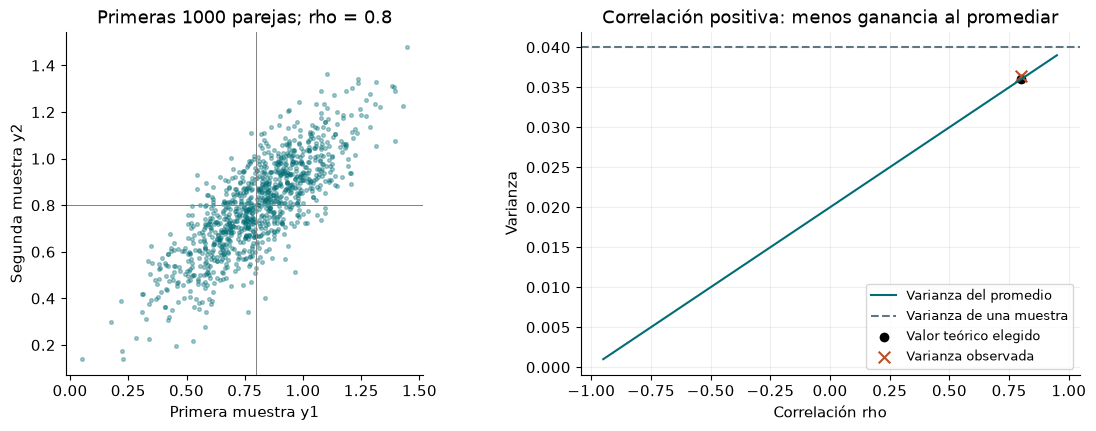

Covarianza teórica: [[0.04  0.032]
 [0.032 0.04 ]]
Covarianza observada: [[0.04046 0.03236]
 [0.03236 0.04041]]
Varianza del promedio: teoría 0.03600; muestras 0.03640.
Varianza relativa a una muestra: 0.900.


In [3]:
rng=np.random.default_rng(semilla);z=rng.standard_normal((2,n_muestras))
y1=h+sigma*z[0];y2=h+sigma*(rho*z[0]+np.sqrt(1-rho*rho)*z[1])
promedio=(y1+y2)/2;C_emp=np.cov(np.vstack([y1,y2]),ddof=1)
var_teorica=sigma**2*(1+rho)/2;var_emp=np.var(promedio,ddof=1)
fig,axes=plt.subplots(1,2,figsize=(11,4.2),layout='constrained')
axes[0].scatter(y1[:1000],y2[:1000],s=7,alpha=.35,c='#006d75')
axes[0].axvline(h,c='gray',lw=.7);axes[0].axhline(h,c='gray',lw=.7)
axes[0].set(xlabel='Primera muestra y1',ylabel='Segunda muestra y2',title=f'Primeras 1000 parejas; rho = {rho:g}',aspect='equal')
rs=np.linspace(-.95,.95,301)
axes[1].plot(rs,sigma**2*(1+rs)/2,label='Varianza del promedio',color='#006d75')
axes[1].axhline(sigma**2,c='#617583',ls='--',label='Varianza de una muestra')
axes[1].scatter([rho],[var_teorica],c='black',label='Valor teórico elegido')
axes[1].scatter([rho],[var_emp],marker='x',s=70,c='#b95028',label='Varianza observada')
axes[1].set(xlabel='Correlación rho',ylabel='Varianza',title='Correlación positiva: menos ganancia al promediar')
axes[1].legend(fontsize=9);axes[1].grid(alpha=.2);plt.show()
print('Covarianza teórica:',np.round(sigma**2*np.array([[1,rho],[rho,1]]),5))
print('Covarianza observada:',np.round(C_emp,5))
print(f'Varianza del promedio: teoría {var_teorica:.5f}; muestras {var_emp:.5f}.')
print(f'Varianza relativa a una muestra: {(1+rho)/2:.3f}.')

## 2. Un canal puede actuar como filtro
Generamos N+1 entradas y conservamos N salidas: la primera usa una entrada anterior generada,
no un cero artificial de arranque. Segmentos: autocorrelación teórica. Cruces: promedios de productos v[n]v[n−k]
de la realización finita. La PSD es una **curva teórica**, no una estimación espectral de las muestras.
Como el proceso es real, es par: ambos lados del eje tienen el mismo valor.

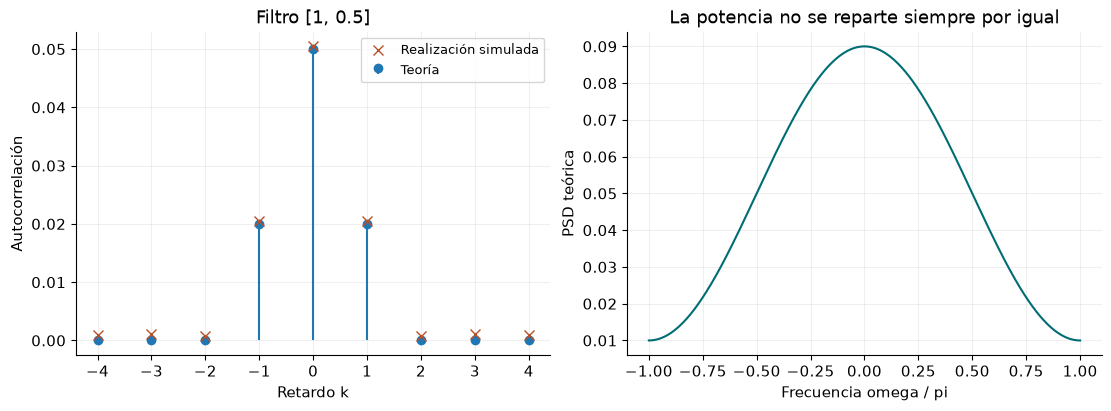

Potencia de salida: teoría 0.05000; realización 0.05046.
Potencia integrando la PSD: 0.05000; Rv[1] = 0.02000.


In [4]:
u=sigma*np.random.default_rng(semilla+1).standard_normal(n_muestras+1)
v=u[1:]+a*u[:-1];retardos=np.arange(-4,5)
r_teo=np.where(retardos==0,sigma**2*(1+a*a),np.where(np.abs(retardos)==1,a*sigma**2,0))
r_pos=np.array([np.mean(v*v)]+[np.mean(v[k:]*v[:-k]) for k in range(1,5)])
r_emp=r_pos[np.abs(retardos)];omega=np.linspace(-np.pi,np.pi,1001)
psd=sigma**2*(1+a*a+2*a*np.cos(omega))
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].stem(retardos,r_teo,basefmt=' ',label='Teoría')
axes[0].plot(retardos,r_emp,'x',c='#b95028',ms=7,label='Realización simulada')
axes[0].set(xlabel='Retardo k',ylabel='Autocorrelación',title=f'Filtro [1, {a:g}]');axes[0].legend(fontsize=9)
axes[1].plot(omega/np.pi,psd,c='#006d75')
axes[1].set(xlabel='Frecuencia omega / pi',ylabel='PSD teórica',title='La potencia no se reparte siempre por igual')
for ax in axes:ax.grid(alpha=.2)
plt.show();potencia_espectral=np.sum((psd[:-1]+psd[1:])*np.diff(omega)/2)/(2*np.pi)
print(f'Potencia de salida: teoría {sigma**2*(1+a*a):.5f}; realización {np.mean(v*v):.5f}.')
print(f'Potencia integrando la PSD: {potencia_espectral:.5f}; Rv[1] = {a*sigma**2:.5f}.')

## Antes de mirar la explicación

1. Compara rho=0, 0.8 y −0.8. ¿Cuánto vale la varianza del promedio respecto a una muestra?
2. ¿Cambiar h modifica la covarianza de los ruidos?
3. Cambia a de 0.5 a −0.5. ¿Dónde se concentra más la potencia?
4. ¿Que la entrada u sea independiente garantiza que la salida v lo sea?

## Explicación de lo observado

1. Las razones son 0.5, 0.9 y 0.1. La correlación positiva hace que los errores tiendan a sumarse;
   la negativa favorece su compensación. Con sigma=0.2 y rho=0.8, la varianza pasa de 0.04 a 0.036.
2. No. h traslada el centro de la nube, sin cambiar las desviaciones respecto a ese centro.
3. Cambia el signo de la correlación a retardo uno. Con a positivo se refuerzan frecuencias próximas a cero;
   con a negativo, las próximas a ±pi. La potencia total es igual para a y −a.
4. No: v[n] y v[n−1] comparten u[n−1]. Con a distinto de cero su covarianza es a sigma²;
   con a=0 recuperamos la entrada. rho no interviene en la segunda parte.

## Comprobación del modelo

Contrastamos identidades y casos conocidos; estas comprobaciones no sustituyen la interpretación.

In [5]:
assert np.isclose(var_emp,(C_emp[0,0]+C_emp[1,1]+2*C_emp[0,1])/4)
assert np.all(np.linalg.eigvalsh(sigma**2*np.array([[1,rho],[rho,1]]))>0)
assert np.allclose(psd,sigma**2*np.abs(1+a*np.exp(-1j*omega))**2)
assert np.isclose(potencia_espectral,r_teo[retardos==0][0])
assert np.allclose(psd,psd[::-1])
if a==0:assert np.allclose(psd,sigma**2)
print('Varianza del promedio, matriz válida, filtro y área de la PSD comprobados.')

Varianza del promedio, matriz válida, filtro y área de la PSD comprobados.


## Referencias

Ejemplo y código propios para TDI.

- TDI, tema 4, apartados 4.4–4.5: «Visualizar la covarianza», «Estacionariedad», «Densidad espectral de potencia» y «Filtrado».
- A. Papoulis y S. U. Pillai, *Probability, Random Variables, and Stochastic Processes*: probabilidad, momentos y procesos.
- J. G. Proakis y M. Salehi, *Digital Communications*: modelos de canal y ruido.

Las condiciones y las derivaciones particulares se explican en «Modelo y pregunta».